# Run a campaign over several years

> Rank areas and resample them every year with a fixed budget

This guide runs a sampling campaign over several years with the same budget each year. The first year ranks the areas from prior knowledge alone. Each later year ranks them from all the measurements collected so far, with the six state variables and weights of Round II in [Getting started](../tutorials/01_getting_started.ipynb).

Each year, `rank_to_sample` with the `quantiles` policy splits the budget across four quartiles of areas by rank. The first quartile shares 50% of the budget, the second 30%, the third 20% and the last none. `min=1` raises every area to at least one sample. The total can then exceed the budget.

In [ ]:
#| hide
import warnings
warnings.filterwarnings('ignore')

## Set up the area

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import geopandas as gpd

from trufl.utils import gridder
from trufl.sampler import Sampler, rank_to_sample
from trufl.collector import DataCollector
from trufl.callbacks import State, MaxCB, MinCB, StdCB, CountCB, MoranICB, PriorCB
from trufl.optimizer import Optimizer

As in the tutorial, the simulated contamination map is the ground truth. A 10 x 10 grid over it gives the administrative units:

In [ ]:
fname_raster = '../files/ground-truth-01-4326-simulated.tif'
gdf_grid = gridder(fname_raster, nrows=10, ncols=10)
sampler = Sampler(gdf_grid)
dc_emulator = DataCollector(fname_raster)

## Set the campaign parameters

In [ ]:
number_of_years = 4
yearly_sample_budget = 150
benefit_criteria = [True, True, True, False, False, True]
weights = [0.2, 0.1, 0.1, 0.2, 0.2, 0.2]

The criteria and weights apply to the state variables in the order of the callbacks: maximum, minimum, standard deviation, sample count, Moran's I and prior.

## Rank the areas for the first year

Before any measurement, the state holds only the prior:

In [ ]:
samples_t0 = gpd.GeoDataFrame(index=pd.Index([], name='loc_id'), geometry=None, data={'value': None})
state_t0 = State(samples_t0, gdf_grid, cbs=[PriorCB(fname_raster)])()
df_rank = Optimizer(state=state_t0).get_rank(is_benefit_x=[True], w_vector=[1],
                                             n_method=None, c_method=None, w_method=None, s_method="CP")

## Sample and re-rank every year

Each year, sample the areas according to the current ranking, add the measurements to those collected so far, then rank the areas again from the new state. Each panel shows the ranking used that year, with all samples so far:

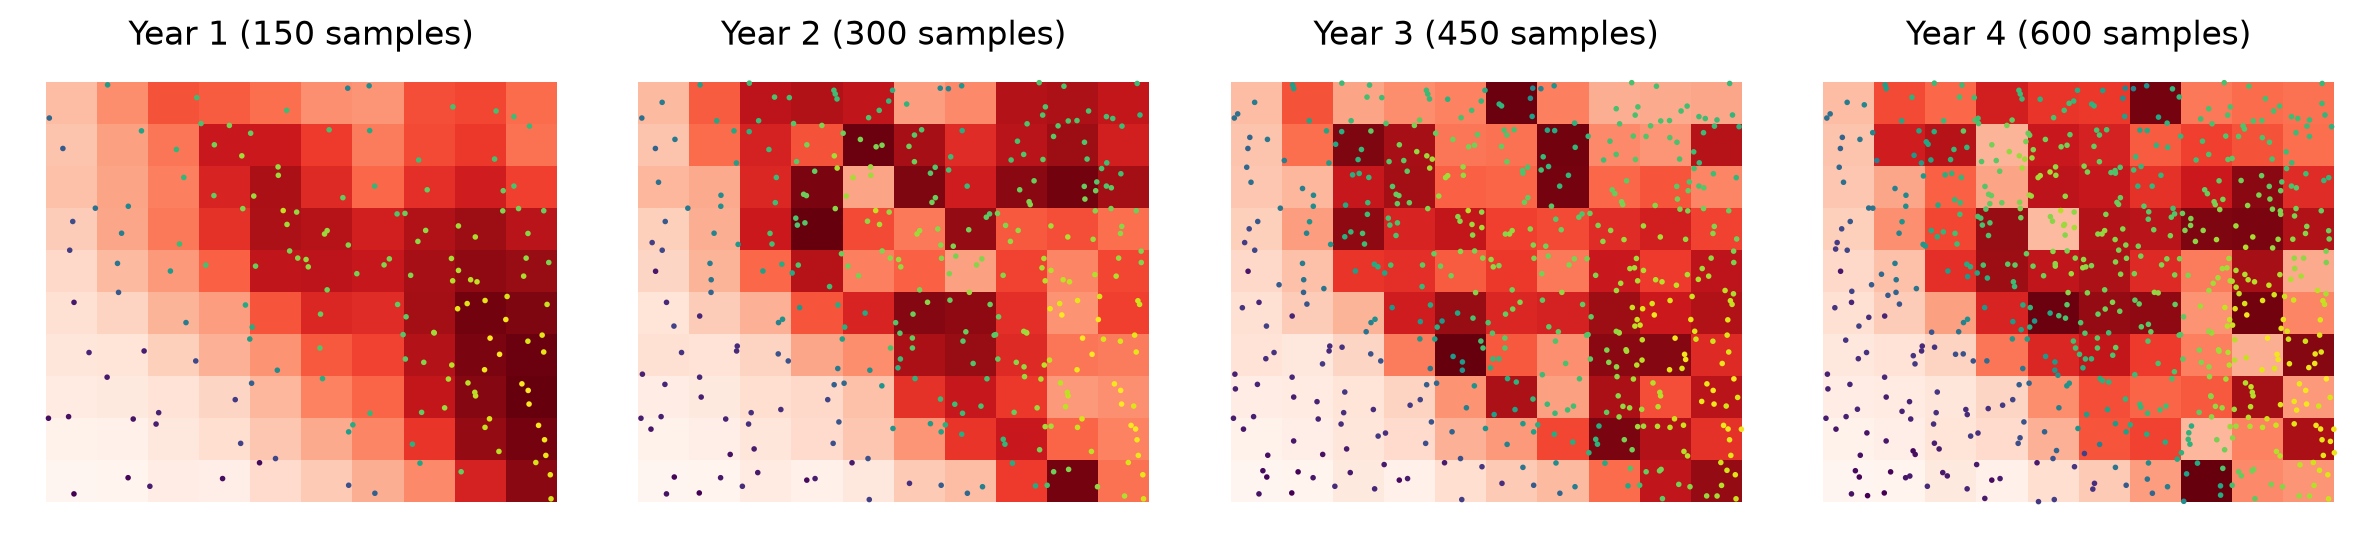

In [ ]:
fig, axs = plt.subplots(1, number_of_years, figsize=(12, 4))
samples = []
for year, ax in enumerate(axs, start=1):
    n = rank_to_sample(df_rank['rank'].sort_index().values, budget=yearly_sample_budget, min=1, policy="quantiles")
    samples.append(dc_emulator.collect(sampler.sample(n, method='uniform')))
    samples_sofar = pd.concat(samples)

    gdf_grid.join(df_rank).plot(column='rank', cmap='Reds_r', ax=ax)
    samples_sofar.plot(column='value', cmap='viridis', s=1, ax=ax)
    ax.set_title(f"Year {year} ({len(samples_sofar)} samples)")
    ax.axis('off')

    state = State(samples_sofar, gdf_grid, cbs=[
        MaxCB(), MinCB(), StdCB(), CountCB(), MoranICB(k=5), PriorCB(fname_raster)])
    df_rank = Optimizer(state=state()).get_rank(is_benefit_x=benefit_criteria, w_vector=weights,
                                                n_method="LINEAR1", c_method=None, w_method=None, s_method="CP")
plt.tight_layout()